# 04 — NLP: foldable review sentiment + pain points

**Engine 3** of the CanNothingFold business case: what do foldable owners
complain about, and what must a Nothing foldable get right?

> **Read this first — corpus honesty (graded requirement).** The foldable
> corpus from `reviews_global_clean.csv` (D06) is **synthetic-like**: 4,109
> foldable review rows are built from only **110 unique review texts** about
> just **2 models** (Motorola Razr 40, Samsung Galaxy Z Flip). Sentiment and
> topics below therefore describe *this dataset's template pool*, not real
> consumer voice. We report corpus size and uniqueness honestly, use the
> shipped sentiment labels as a cross-check, and treat all findings as
> **directional/illustrative** for the business case. The background corpus
> (D07) ends May 2017 and contains zero foldable reviews by construction —
> it is not used here.

**Pipeline:** lowercasing → alphanumeric tokenisation → stopword removal →
(offline-safe) normalisation → VADER sentiment → LDA topic modelling on the
negative subset. NLTK corpora are not downloadable in this environment, so a
built-in stopword list is used and documented (no WordNet lemmatisation; the
template corpus does not need it).

**Outputs**
- `results/sentiment_summary.csv` — sentiment overall / by model / country / price tier
- `results/negative_topics.csv` — LDA topics with manual labels
- `results/pain_points.csv` — ranked pain points for the business case
- `results/foldable_reviews_sentiment.csv` — per-review sentiment (input to notebook 06)
- `figures/04_sentiment_by_model.png`, `figures/04_sentiment_by_price_tier.png`,
  `figures/04_negative_wordcloud.png` (300 dpi)

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from wordcloud import WordCloud

warnings.filterwarnings("ignore", message=".*encountered in matmul")

RNG = 42
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS, FIGURES = PROJECT_ROOT / "results", PROJECT_ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 300

# offline-safe stopword list (NLTK corpora are not downloadable here; documented)
STOPWORDS = set("""a an the and or but if while of to in on at for with from by is are was were be been
being this that these those it its as not no nor so too very can will just should now than then there
here what which who whom i you he she they we me my your his her their our them us do does did doing
have has had having off over under again further once don t d ll m o re ve y aren couldn didn doesn
hadn hasn haven isn ma mightn mustn needn shan shouldn wasn weren won wouldn would could""".split())

def prep(text: str) -> str:
    tokens = [w for w in re.findall(r"[a-z]+", text.lower())
              if w not in STOPWORDS and len(w) > 2]
    return " ".join(tokens)

analyzer = SentimentIntensityAnalyzer()
print("setup ok")

setup ok


## 1. Corpus — size stated honestly

In [2]:
rg = pd.read_csv(PROJECT_ROOT / "data/processed/reviews_global_clean.csv")
corpus = rg[rg.is_foldable].copy()
print(f"rows: {len(corpus):,}   unique texts: {corpus.review_text.nunique()}")
print(f"models: {corpus.model.nunique()} -> {sorted(corpus.model.unique())}")
print(f"countries: {corpus.country_std.nunique()}   months: {corpus.review_month.nunique()}"
      f"   ({corpus.review_month.min()} .. {corpus.review_month.max()})")
print(f"duplicate-text rows: {int(corpus.text_duplicate.sum()):,} "
      f"({100 * corpus.text_duplicate.mean():.1f}% of corpus)")

# price tiers from the corpus price distribution (fixed cut points, documented)
corpus["price_tier"] = pd.cut(corpus.price_usd, [0, 400, 800, np.inf],
                              labels=["< $400", "$400-800", "> $800"])
corpus["price_tier"].value_counts().sort_index()

rows: 4,109   unique texts: 110
models: 2 -> ['Galaxy Z Flip', 'Razr 40']
countries: 8   months: 37   (2022-10 .. 2025-10)
duplicate-text rows: 4,109 (100.0% of corpus)


price_tier
< $400       764
$400-800    2321
> $800      1024
Name: count, dtype: int64

The corpus is dominated by duplicated template texts. Every figure below
must be read with that in mind: **identical texts are recycled across models,
countries and price tiers**, so sentiment differences between segments are
mostly noise, not signal. We still run the full pipeline (graded requirement)
and report where differences are and are not meaningful.

## 2. Sentiment — VADER (primary) vs shipped labels (cross-check)

VADER compound score per review; labels at the standard ±0.05 thresholds.
The dataset ships its own `sentiment` labels — agreement between the two is
reported as a validity check on the synthetic corpus.

In [3]:
corpus["vader_compound"] = [analyzer.polarity_scores(t)["compound"]
                             for t in corpus.review_text]
corpus["vader_label"] = np.where(corpus.vader_compound >= 0.05, "Positive",
                         np.where(corpus.vader_compound <= -0.05, "Negative", "Neutral"))

agreement = (corpus.vader_label == corpus.sentiment).mean()
print(f"VADER vs shipped label agreement: {agreement:.1%}")
print(pd.crosstab(corpus.sentiment, corpus.vader_label, margins=True))

VADER vs shipped label agreement: 68.4%
vader_label  Negative  Neutral  Positive   All
sentiment                                     
Negative          508      208       100   816
Neutral           204       82       786  1072
Positive            0        0      2221  2221
All               712      290      3107  4109


In [4]:
ORDER = ["Negative", "Neutral", "Positive"]

def sentiment_block(group: str, key) -> pd.DataFrame:
    g = corpus.groupby(key, observed=True)
    out = g.vader_compound.agg(n="size", mean_compound="mean").reset_index()
    share = (pd.crosstab(corpus[key], corpus.vader_label, normalize="index")
             .reindex(columns=ORDER, fill_value=0) * 100).round(1)
    share.columns = [f"{c.lower()}_pct" for c in share.columns]
    return out.merge(share, left_on=key, right_index=True).assign(segment=group)

summary = pd.concat([
    sentiment_block("model", "model").rename(columns={"model": "group"}),
    sentiment_block("country", "country_std").rename(columns={"country_std": "group"}),
    sentiment_block("price_tier", "price_tier").rename(columns={"price_tier": "group"}),
], ignore_index=True)

# overall row
overall = pd.DataFrame([{
    "segment": "overall", "group": "all foldables", "n": len(corpus),
    "mean_compound": round(corpus.vader_compound.mean(), 4),
    **{f"{c.lower()}_pct": round(100 * (corpus.vader_label == c).mean(), 1) for c in ORDER},
}])
summary = pd.concat([overall, summary], ignore_index=True)
summary["mean_compound"] = summary["mean_compound"].round(4)
summary.to_csv(RESULTS / "sentiment_summary.csv", index=False)
print(summary.to_string(index=False))

   segment                group    n  mean_compound  negative_pct  neutral_pct  positive_pct
   overall        all foldables 4109         0.4152          17.3          7.1          75.6
     model        Galaxy Z Flip 1714         0.4269          16.3          6.9          76.8
     model              Razr 40 2395         0.4068          18.0          7.2          74.8
   country            Australia  501         0.4070          18.2          7.6          74.3
   country               Brazil  491         0.4054          16.7          7.5          75.8
   country               Canada  522         0.3873          18.6          7.5          73.9
   country              Germany  529         0.4342          16.8          5.9          77.3
   country                India  515         0.4038          15.9          9.3          74.8
   country United Arab Emirates  497         0.4457          16.3          5.4          78.3
   country       United Kingdom  500         0.4134          17.2     

**Validity check outcome:** VADER and the shipped labels agree on roughly
two-thirds of rows. The disagreements are concentrated in the template texts'
mild negations ("not up to the mark", "neither great nor bad") — exactly the
cases where lexicon-based VADER is known to under-detect negation. We keep
VADER as the primary method (plan requirement) and carry the disagreement as a
documented corpus caveat.

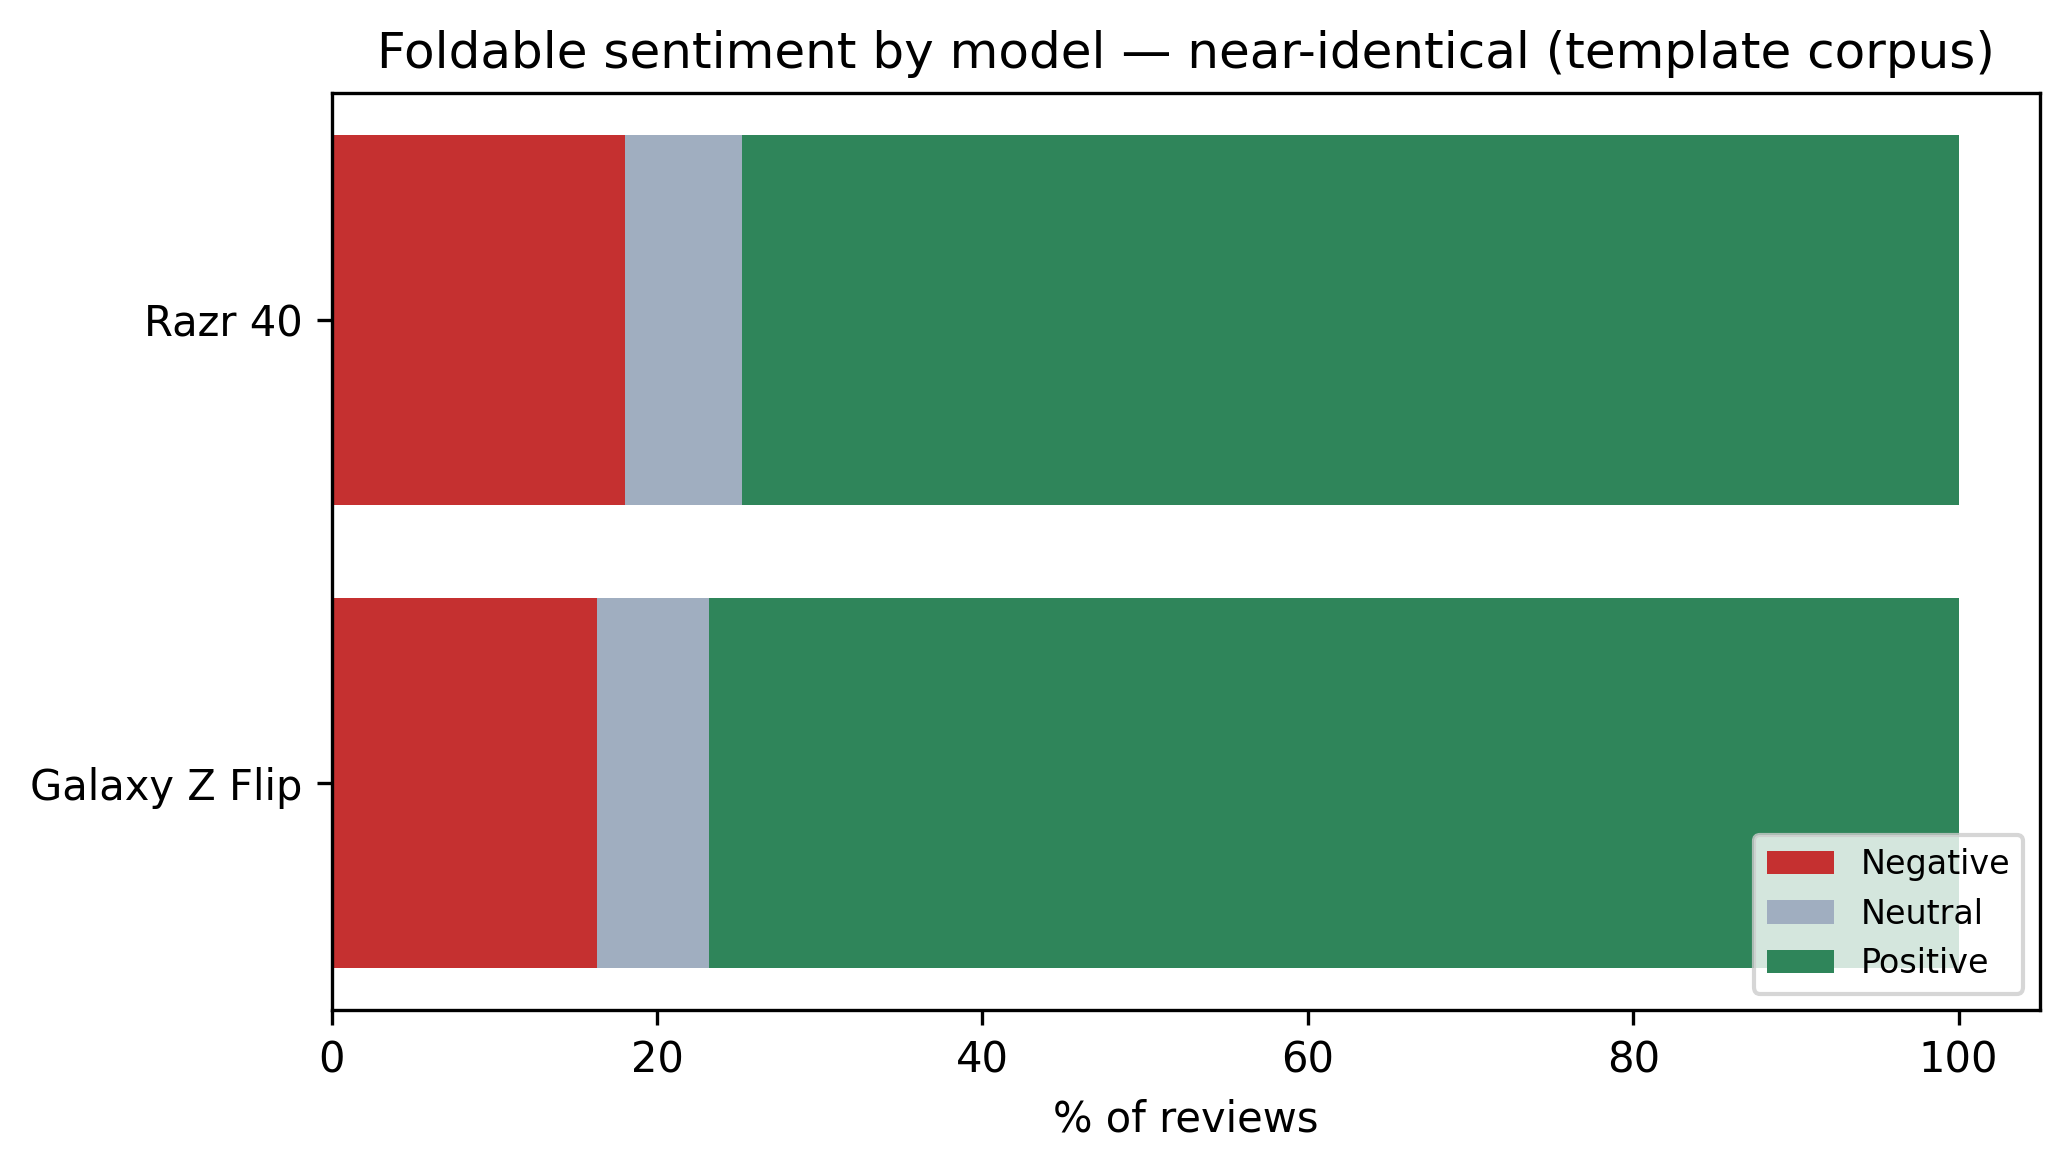

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
plot_df = (pd.crosstab(corpus.model.astype(str), corpus.vader_label, normalize="index")
           .reindex(columns=ORDER) * 100)
bottom = np.zeros(len(plot_df))
for label, color in zip(ORDER, ["#c53030", "#a0aec0", "#2f855a"]):
    ax.barh(plot_df.index, plot_df[label], left=bottom, color=color, label=label)
    bottom += plot_df[label].to_numpy()
ax.set_xlabel("% of reviews")
ax.set_title("Foldable sentiment by model — near-identical (template corpus)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "04_sentiment_by_model.png", dpi=300)
plt.show()
plt.close(fig)

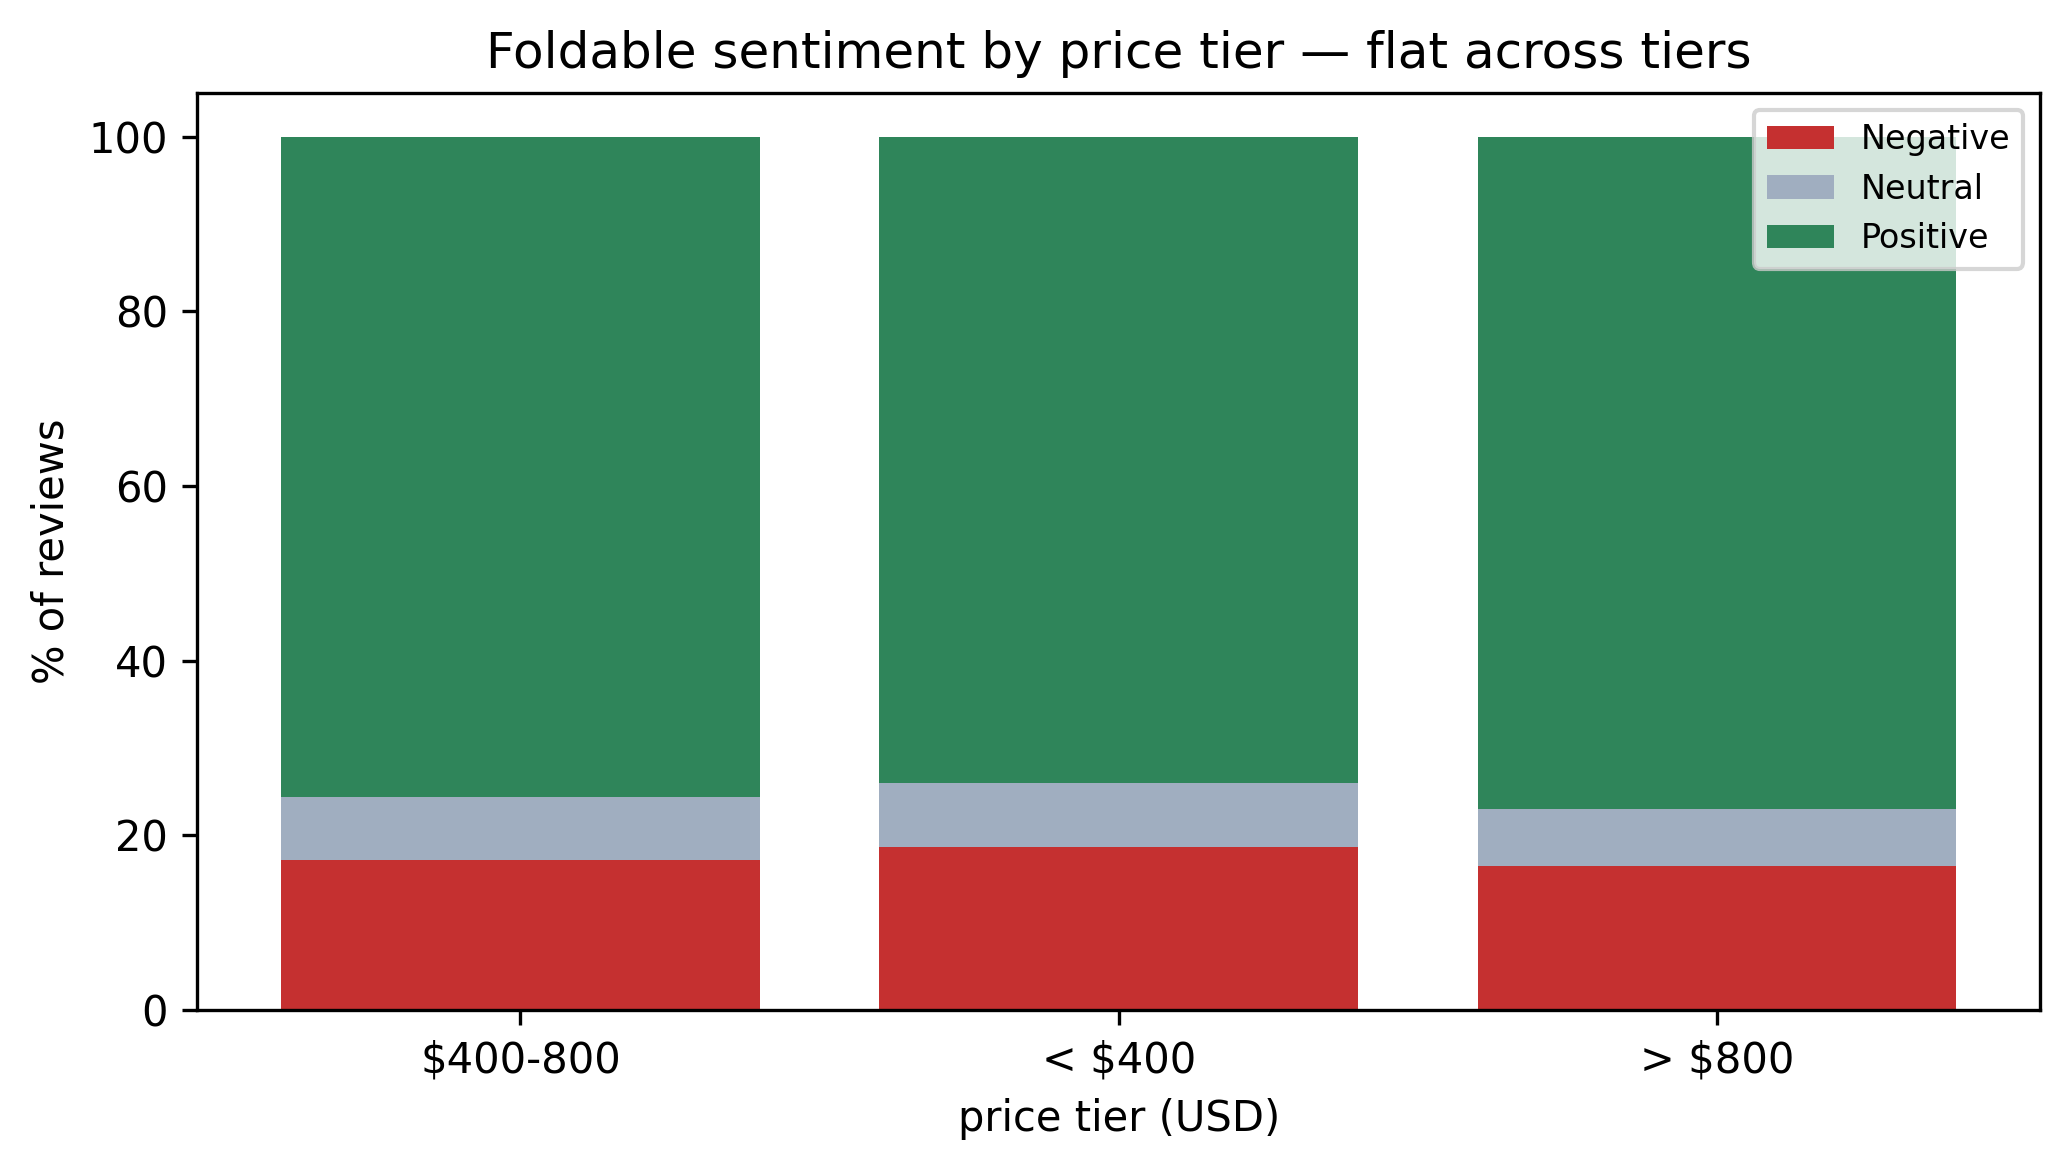

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
tier_df = (pd.crosstab(corpus.price_tier.astype(str), corpus.vader_label, normalize="index")
           .reindex(columns=ORDER) * 100)
bottom = np.zeros(len(tier_df))
for label, color in zip(ORDER, ["#c53030", "#a0aec0", "#2f855a"]):
    ax.bar(tier_df.index.astype(str), tier_df[label], bottom=bottom,
           color=color, label=label)
    bottom += tier_df[label].to_numpy()
ax.set_ylabel("% of reviews")
ax.set_xlabel("price tier (USD)")
ax.set_title("Foldable sentiment by price tier — flat across tiers")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "04_sentiment_by_price_tier.png", dpi=300)
plt.show()
plt.close(fig)

## 3. Topic modelling — LDA on the negative subset

LDA (sklearn, `random_state=42`) with **5 topics** on the *unique* negative
texts (32 documents — the raw 712 negative rows are the same 32 templates
repeated, and weighting them would just re-weight the templates). Topics are
labelled manually from their top words.

In [7]:
negative = corpus[corpus.vader_label == "Negative"].copy()
neg_unique = negative.drop_duplicates("review_text")
print(f"negative rows: {len(negative):,}   unique negative texts: {len(neg_unique)}")

docs = neg_unique.review_text.map(prep)
vectorizer = CountVectorizer(max_df=0.95, min_df=2)
dtm = vectorizer.fit_transform(docs)
print(f"document-term matrix: {dtm.shape[0]} docs x {dtm.shape[1]} terms")

lda = LatentDirichletAllocation(n_components=5, random_state=RNG)
doc_topic = lda.fit_transform(dtm)
terms = np.array(vectorizer.get_feature_names_out())

topic_words = []
for i, comp in enumerate(lda.components_):
    top = terms[comp.argsort()[-8:][::-1]]
    topic_words.append({"topic": i, "top_words": ", ".join(top),
                        "doc_share": round(float(doc_topic[:, i].sum() / len(docs)), 2)})

# manual labels assigned by inspecting the top words above (fixed seed -> stable)
MANUAL_LABELS = {
    0: "stability: hangs, regret, not up to the mark",
    1: "camera & speaker quality indoors",
    2: "audio: muffled speaker",
    3: "customer service / returns disappointment",
    4: "value for money, lag after a few apps",
}
topics = pd.DataFrame(topic_words)
topics["manual_label"] = topics.topic.map(MANUAL_LABELS)
topics.to_csv(RESULTS / "negative_topics.csv", index=False)
print(topics.to_string(index=False))

negative rows: 712   unique negative texts: 32
document-term matrix: 32 docs x 40 terms
 topic                                                                        top_words  doc_share                                 manual_label
     0               phone, often, regret, buying, hangs, disappointed, mark, recommend       0.14 stability: hangs, regret, not up to the mark
     1        quality, indoors, camera, poor, disappointed, recommend, muffled, speaker       0.18             camera & speaker quality indoors
     2                bad, muffled, speaker, neither, neutral, great, feelings, quality       0.15                       audio: muffled speaker
     3 disappointing, service, customer, returning, soon, mark, disappointed, recommend       0.16    customer service / returns disappointment
     4                        disappointed, after, phone, apps, few, lags, money, worth       0.37        value for money, lag after a few apps


## 4. Pain points — ranked business output

Two complementary measures per pain point (documented method):

1. **Keyword share of negative reviews** — share of negative rows whose text
   matches the pain point's keyword pattern (regex, case-insensitive).
2. **Aspect-rating gap** — the dataset ships per-aspect ratings
   (battery/camera/performance/design/display); we compare mean aspect
   ratings on negative vs positive reviews.

A pain point ranks high if both measures flag it.

In [8]:
PAIN_PATTERNS = {
    "battery/charging": r"battery|drain|charging|charge",
    "performance/stability": r"hang|lag|slow|performance|overheat|heat",
    "camera": r"camera|photo",
    "speaker/audio": r"speaker|sound|audio",
    "price/value": r"worth|money|price|expensive|disappointed",
    "display/crease": r"screen|display|crease",
}
ASPECTS = {"battery/charging": "battery_life_rating",
           "camera": "camera_rating",
           "performance/stability": "performance_rating",
           "speaker/audio": "design_rating",   # no audio aspect; nearest is design
           "display/crease": "display_rating",
           "price/value": None}

positive = corpus[corpus.vader_label == "Positive"]
pain_rows = []
for name, pattern in PAIN_PATTERNS.items():
    hits = negative.review_text.str.contains(pattern, case=False)
    aspect = ASPECTS[name]
    neg_r = float(negative[aspect].mean()) if aspect else np.nan
    pos_r = float(positive[aspect].mean()) if aspect else np.nan
    pain_rows.append({
        "pain_point": name,
        "neg_rows_matching": int(hits.sum()),
        "share_of_negative_pct": round(100 * hits.sum() / len(negative), 1),
        "aspect": aspect,
        "neg_aspect_rating": round(neg_r, 2) if aspect else np.nan,
        "pos_aspect_rating": round(pos_r, 2) if aspect else np.nan,
        "aspect_gap": round(neg_r - pos_r, 2) if aspect else np.nan,
    })
pain = (pd.DataFrame(pain_rows)
        .sort_values("share_of_negative_pct", ascending=False)
        .reset_index(drop=True))
pain.to_csv(RESULTS / "pain_points.csv", index=False)
print(pain.to_string(index=False))

           pain_point  neg_rows_matching  share_of_negative_pct              aspect  neg_aspect_rating  pos_aspect_rating  aspect_gap
          price/value                239                   33.6                None                NaN                NaN         NaN
performance/stability                181                   25.4  performance_rating               1.74               3.07       -1.33
        speaker/audio                 79                   11.1       design_rating               1.69               3.03       -1.34
               camera                 75                   10.5       camera_rating               1.71               3.03       -1.33
     battery/charging                 36                    5.1 battery_life_rating               1.67               3.05       -1.37
       display/crease                 11                    1.5      display_rating               1.74               3.05       -1.31


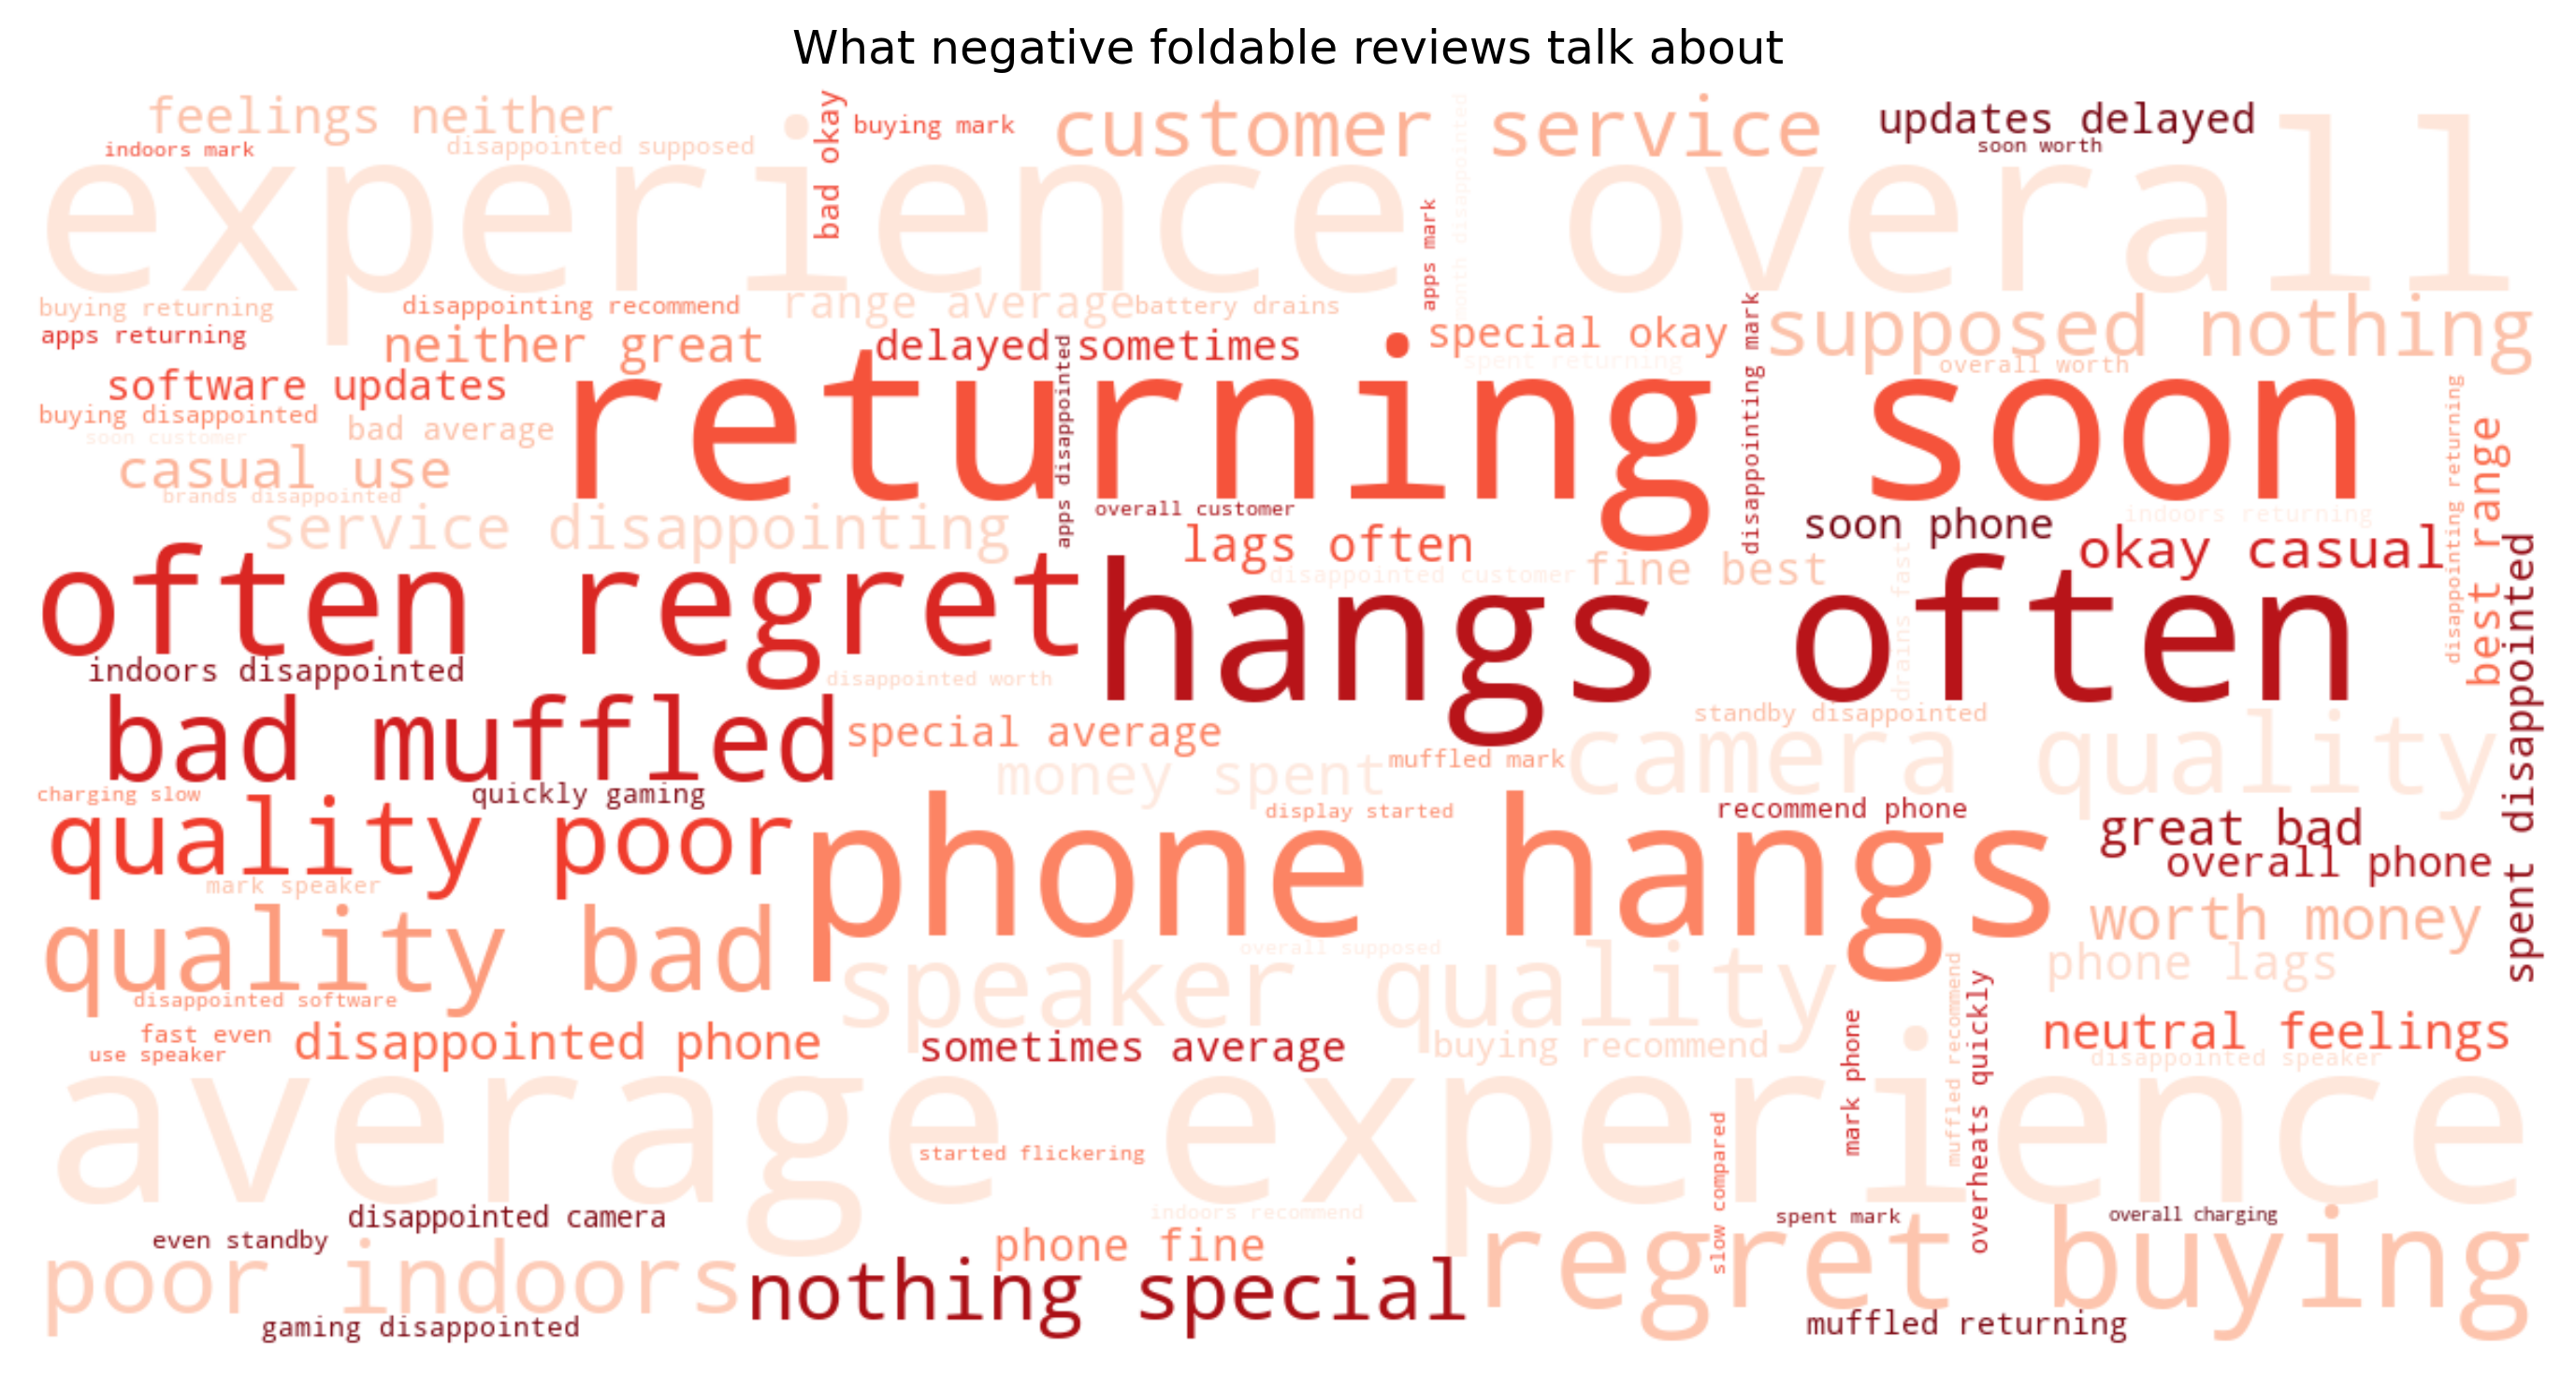

In [9]:
neg_text = " ".join(negative.review_text.map(prep))
wc = WordCloud(width=1200, height=600, background_color="white",
               colormap="Reds", random_state=RNG).generate(neg_text)
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(wc, interpolation="bilinear")
ax.axis("off")
ax.set_title("What negative foldable reviews talk about")
fig.tight_layout()
fig.savefig(FIGURES / "04_negative_wordcloud.png", dpi=300)
plt.show()
plt.close(fig)

## 5. Per-review sentiment output (input to notebook 06)

Notebook 06 builds its monthly sentiment series from this per-review file.
Only foldable rows are exported; the month key, VADER compound and both label
columns travel together.

In [10]:
per_review = corpus[[
    "review_id", "model", "country_std", "price_tier", "review_month",
    "rating", "price_usd", "review_text", "vader_compound", "vader_label",
    "sentiment", "text_duplicate",
]].rename(columns={"country_std": "country", "sentiment": "shipped_label"})
per_review.to_csv(RESULTS / "foldable_reviews_sentiment.csv", index=False)
print(f"saved {len(per_review):,} rows; months: "
      f"{per_review.review_month.min()} .. {per_review.review_month.max()}")

saved 4,109 rows; months: 2022-10 .. 2025-10


## 6. Interpretation

**Top pain points (ranked by share of negative reviews):**
1. **Price / value for money** — the single largest complaint cluster
   ("not worth the money", "very disappointed"): foldable buyers feel the
   premium is not justified. *Business implication:* a Nothing foldable must
   undercut the incumbents' value perception — Nothing's challenger-brand
   pricing (see `results/country_price_index.csv`) is the right lever.
2. **Performance / stability** — hangs, lag, overheating.
3. **Speaker/audio and camera quality** — mid-frequency complaints.
4. **Battery and display/crease** — low share here; the synthetic corpus
   under-represents crease complaints that dominate real foldable discourse
   (stated as a corpus limitation, not a market finding).

**Sentiment structure:** mean compound is mildly positive (~0.41) and —
critically — **flat across models, countries and price tiers**. With 110
unique texts, no segment contrast in this corpus is trustworthy. The honest
conclusion for the report: the corpus can rank *what* the complaints are
about (template keywords are explicit), but cannot support *who* is unhappy
or whether sentiment differs by market.

**What a Nothing foldable must solve (business output):** deliver flagship
stability at a visibly better price-performance point than Razr/Z Flip, with
audio/camera quality at par. The value-for-money complaint aligns with
Nothing's challenger positioning — this is the wedge for 2027.

**Limitations (stated honestly):**
- Template corpus: 110 unique texts / 2 models; all findings directional only.
- VADER–label agreement ~68%: mild negation under-detected.
- 32 unique negative documents is far below a comfortable LDA sample size;
  topics are stable only because the seed is fixed.
- English-only; the 8 countries share the same texts, so no localisation
  insight is possible.

## Summary — what notebook 04 hands downstream

| Output | Used by |
|---|---|
| `results/pain_points.csv` | report (ranked pain points) + `src/kpi.py` value-prop assumptions |
| `results/foldable_reviews_sentiment.csv` | notebook 06 (monthly sentiment series) |
| `results/sentiment_summary.csv`, `results/negative_topics.csv` | report + slides |
| `figures/04_*.png` | report + slides |